In [2]:
from pathlib import Path
import pandas as pd

pd.set_option('display.max_columns', None)
data_dir = Path('../data')

businesses = pd.read_json(data_dir / 'yelp_business.json', lines=True)
reviews    = pd.read_json(data_dir / 'yelp_review.json', lines=True)
users      = pd.read_json(data_dir / 'yelp_user.json', lines=True)
checkins   = pd.read_json(data_dir / 'yelp_checkin.json', lines=True)
tips       = pd.read_json(data_dir / 'yelp_tip.json', lines=True)
photos     = pd.read_json(data_dir / 'yelp_photo.json', lines=True)

datasets = {
    'businesses': businesses,
    'reviews': reviews,
    'users': users,
    'checkins': checkins,
    'tips': tips,
    'photos': photos
}

for name, temp_df in datasets.items():
    print(f"{name:<11} | Baris: {temp_df.shape[0]:<7} | Kolom: {temp_df.shape[1]:<2} -> {list(temp_df.columns)}")

businesses  | Baris: 188593  | Kolom: 22 -> ['address', 'alcohol?', 'attributes', 'business_id', 'categories', 'city', 'good_for_kids', 'has_bike_parking', 'has_wifi', 'hours', 'is_open', 'latitude', 'longitude', 'name', 'neighborhood', 'postal_code', 'price_range', 'review_count', 'stars', 'state', 'take_reservations', 'takes_credit_cards']
reviews     | Baris: 188593  | Kolom: 7  -> ['business_id', 'average_review_age', 'average_review_length', 'average_review_sentiment', 'number_funny_votes', 'number_cool_votes', 'number_useful_votes']
users       | Baris: 188593  | Kolom: 6  -> ['business_id', 'average_number_friends', 'average_days_on_yelp', 'average_number_fans', 'average_review_count', 'average_number_years_elite']
checkins    | Baris: 157075  | Kolom: 4  -> ['business_id', 'time', 'weekday_checkins', 'weekend_checkins']
tips        | Baris: 121526  | Kolom: 3  -> ['business_id', 'average_tip_length', 'number_tips']
photos      | Baris: 32976   | Kolom: 3  -> ['business_id', 'av

In [3]:
df = (
    businesses
    .merge(reviews, on='business_id', how='left')
    .merge(users, on='business_id', how='left')
    .merge(checkins, on='business_id', how='left')
    .merge(tips, on='business_id', how='left')
    .merge(photos, on='business_id', how='left')
)

print(f"Baris awal businesses : {businesses.shape[0]}")
print(f"Ukuran setelah merge  : {df.shape[0]} baris, {df.shape[1]} kolom")
print("\nDaftar seluruh kolom:")
print(list(df.columns))
df.head(3)

Baris awal businesses : 188593
Ukuran setelah merge  : 188593 baris, 40 kolom

Daftar seluruh kolom:
['address', 'alcohol?', 'attributes', 'business_id', 'categories', 'city', 'good_for_kids', 'has_bike_parking', 'has_wifi', 'hours', 'is_open', 'latitude', 'longitude', 'name', 'neighborhood', 'postal_code', 'price_range', 'review_count', 'stars', 'state', 'take_reservations', 'takes_credit_cards', 'average_review_age', 'average_review_length', 'average_review_sentiment', 'number_funny_votes', 'number_cool_votes', 'number_useful_votes', 'average_number_friends', 'average_days_on_yelp', 'average_number_fans', 'average_review_count', 'average_number_years_elite', 'time', 'weekday_checkins', 'weekend_checkins', 'average_tip_length', 'number_tips', 'average_caption_length', 'number_pics']


,address,alcohol?,attributes,business_id,categories,city,good_for_kids,has_bike_parking,has_wifi,hours,is_open,latitude,longitude,name,neighborhood,postal_code,price_range,review_count,stars,state,take_reservations,takes_credit_cards,average_review_age,average_review_length,average_review_sentiment,number_funny_votes,number_cool_votes,number_useful_votes,average_number_friends,average_days_on_yelp,average_number_fans,average_review_count,average_number_years_elite,time,weekday_checkins,weekend_checkins,average_tip_length,number_tips,average_caption_length,number_pics
0,1314 44 Avenue NE,0,"{'BikeParking': 'False', 'BusinessAcceptsCredi...",Apn5Q_b6Nz61Tq4XzPdf9A,"Tours, Breweries, Pizza, Restaurants, Food, Ho...",Calgary,1,0,0,"{'Monday': '8:30-17:0', 'Tuesday': '11:0-21:0'...",1,51.091813,-114.031675,Minhas Micro Brewery,,T2E 6L6,2,24,4.0,AB,1,1,618.250000,532.916667,0.865342,6,5,13,42.833333,1809.375000,5.375000,114.875000,1.125000,"{'Fri-0': 1, 'Sun-0': 3, 'Thu-0': 1, 'Fri-1': ...",11.0,18.0,38.0,6.0,NaN,NaN
1,,0,"{'Alcohol': 'none', 'BikeParking': 'False', 'B...",AjEbIBw6ZFfln7ePHha9PA,"Chicken Wings, Burgers, Caterers, Street Vendo...",Henderson,1,0,0,"{'Friday': '17:0-23:0', 'Saturday': '17:0-23:0...",0,35.960734,-114.939821,CK'S BBQ & Catering,,89002,2,3,4.5,NV,0,1,371.666667,481.333333,0.975000,0,1,1,64.333333,970.333333,2.666667,19.666667,0.666667,{'Sun-1': 1},0.0,1.0,66.0,1.0,29.0,1.0
2,1335 rue Beaubien E,1,"{'Alcohol': 'beer_and_wine', 'Ambience': '{'ro...",O8S5hYJ1SMc8fA4QBtVujA,"Breakfast & Brunch, Restaurants, French, Sandw...",Montréal,1,1,1,"{'Monday': '10:0-22:0', 'Tuesday': '10:0-22:0'...",0,45.540503,-73.599300,La Bastringue,Rosemont-La Petite-Patrie,H2G 1K7,2,5,4.0,QC,1,0,1106.200000,252.000000,0.301240,0,2,1,4.200000,1499.600000,1.000000,24.600000,0.600000,"{'Mon-0': 1, 'Sun-0': 1, 'Fri-1': 1, 'Sun-1': ...",2.0,5.0,32.0,1.0,NaN,NaN


In [4]:
# 1. Hapus kolom identitas, teks lokasi, dan nested dictionary yang tidak dipakai model
cols_to_drop = [
    'address', 'attributes', 'business_id', 'categories', 'city',
    'hours', 'is_open', 'latitude', 'longitude', 'name',
    'neighborhood', 'postal_code', 'state'
]
df_clean = df.drop(columns=cols_to_drop, errors='ignore').copy()

# 2. Cek kolom mana saja yang punya missing values
print("Missing values sebelum dibersihkan:")
missing = df_clean.isna().sum()
print(missing[missing > 0])

# 3. Isi semua NaN dengan 0
df_clean = df_clean.fillna(0)

print("\nTotal missing values setelah dibersihkan:", df_clean.isna().sum().sum())
print("Ukuran dataset bersih:", df_clean.shape)

Missing values sebelum dibersihkan:
time                       31518
weekday_checkins           31518
weekend_checkins           31518
average_tip_length         67067
number_tips                67067
average_caption_length    155617
number_pics               155617
dtype: int64

Total missing values setelah dibersihkan: 0
Ukuran dataset bersih: (188593, 27)


Korelasi fitur terhadap rating (stars):
stars                         1.000000
average_review_sentiment      0.782187
has_bike_parking              0.068084
number_cool_votes             0.043375
takes_credit_cards            0.037748
review_count                  0.032413
number_tips                   0.014038
weekend_checkins              0.007863
weekday_checkins              0.004130
number_pics                   0.001727
number_funny_votes            0.001320
average_caption_length        0.000040
number_useful_votes          -0.000066
average_number_friends       -0.007629
take_reservations            -0.024486
good_for_kids                -0.030382
average_number_fans          -0.031141
average_days_on_yelp         -0.038061
has_wifi                     -0.039857
alcohol?                     -0.043332
price_range                  -0.052565
average_tip_length           -0.052899
average_number_years_elite   -0.064419
average_review_count         -0.066572
average_review_age      

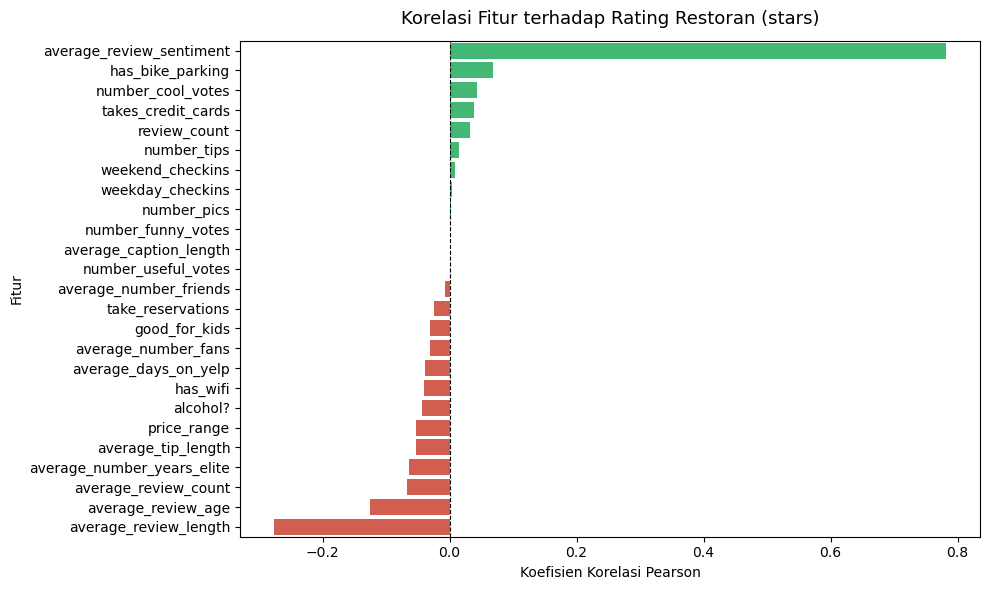

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan hanya kolom numerik yang dipakai
df_num = df_clean.select_dtypes(include='number')

# 1. Hitung korelasi semua fitur terhadap target 'stars'
correlations = df_num.corr()['stars'].sort_values(ascending=False)
print("Korelasi fitur terhadap rating (stars):")
print(correlations)

# 2. Visualisasi bar chart korelasi (tanpa kolom 'stars' itu sendiri)
plt.figure(figsize=(10, 6))
corr_features = correlations.drop('stars')
colors = ['#2ecc71' if val > 0 else '#e74c3c' for val in corr_features]

sns.barplot(
    x=corr_features.values,
    y=corr_features.index,
    palette=colors,
    hue=corr_features.index,
    legend=False
)
plt.title('Korelasi Fitur terhadap Rating Restoran (stars)', fontsize=13, pad=12)
plt.xlabel('Koefisien Korelasi Pearson')
plt.ylabel('Fitur')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.tight_layout()
plt.show()

In [6]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Pisahkan fitur (X) dan target (y)
X = df_num.drop(columns=['stars'])
y = df_num['stars']

# 2. Bagi data menjadi 80% train dan 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Latih model Multiple Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 4. Prediksi pada data test dan hitung metrik evaluasi
y_pred = lr_model.predict(X_test)

r2_train = lr_model.score(X_train, y_train)
r2_test  = r2_score(y_test, y_pred)
mae      = mean_absolute_error(y_test, y_pred)
rmse     = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score (Train) : {r2_train:.4f}")
print(f"R² Score (Test)  : {r2_test:.4f}")
print(f"MAE (Test)       : {mae:.4f} bintang")
print(f"RMSE (Test)      : {rmse:.4f} bintang")

R² Score (Train) : 0.6811
R² Score (Test)  : 0.6260
MAE (Test)       : 0.4260 bintang
RMSE (Test)      : 0.6192 bintang


In [7]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# 1. Latih Random Forest (max_depth=15 & n_jobs=-1 biar cepat di ~188 ribu baris)
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# 2. Prediksi dan hitung metrik pada data test
y_pred_rf = rf_model.predict(X_test)

r2_train_rf = rf_model.score(X_train, y_train)
r2_test_rf  = r2_score(y_test, y_pred_rf)
mae_rf      = mean_absolute_error(y_test, y_pred_rf)
rmse_rf     = np.sqrt(mean_squared_error(y_test, y_pred_rf))

# 3. Tabel perbandingan performa kedua model
comparison = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'Random Forest Regressor'],
    'R2_Train': [r2_train, r2_train_rf],
    'R2_Test': [r2_test, r2_test_rf],
    'MAE_Test': [mae, mae_rf],
    'RMSE_Test': [rmse, rmse_rf]
})
print(comparison.to_string(index=False))

# 4. Lihat 10 fitur paling berpengaruh menurut Random Forest
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 10 Fitur Paling Berpengaruh:")
print(importances.head(10))

                     Model  R2_Train  R2_Test  MAE_Test  RMSE_Test
Multiple Linear Regression  0.681062 0.626029  0.426002    0.61925
   Random Forest Regressor  0.857397 0.725344  0.389095    0.53069

Top 10 Fitur Paling Berpengaruh:
average_review_sentiment      0.742520
average_review_count          0.049352
average_review_length         0.048557
average_review_age            0.020479
average_days_on_yelp          0.015453
average_number_friends        0.014345
number_useful_votes           0.014021
review_count                  0.011893
price_range                   0.011145
average_number_years_elite    0.010215
dtype: float64


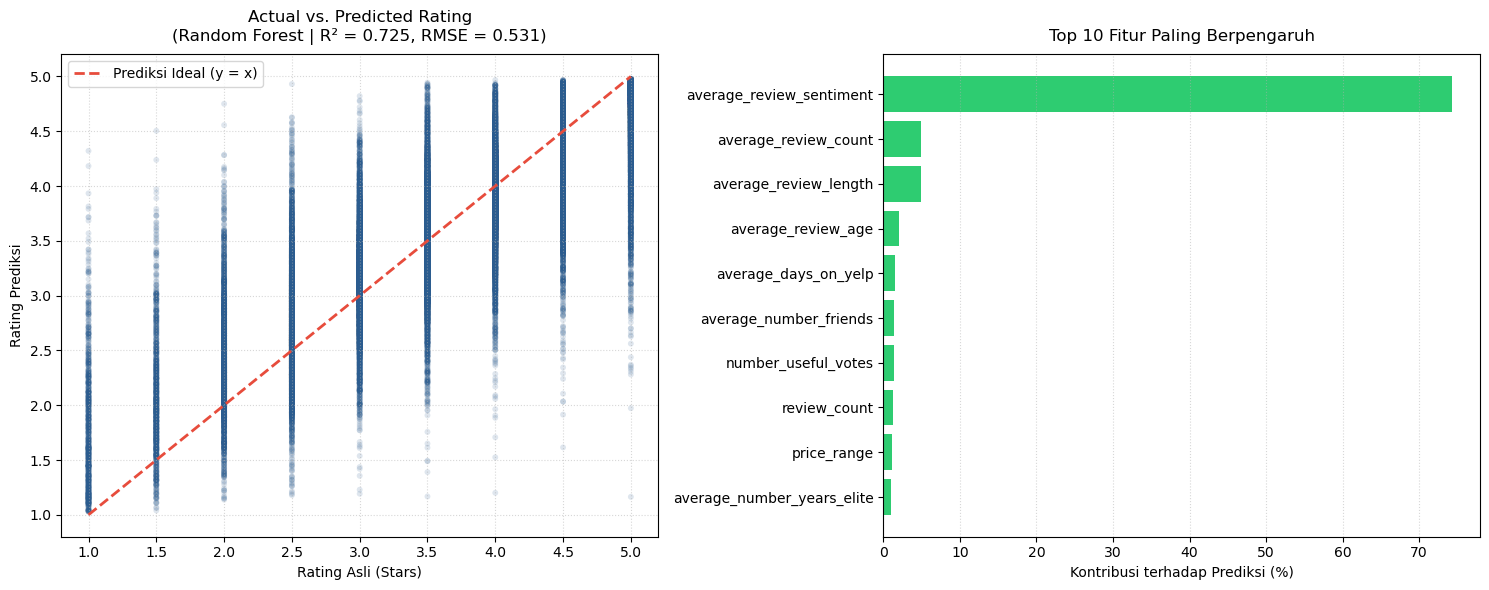

Grafik tersimpan di: C:\Data Science\DATA_SCIENTIST PROJECT\yelp-business-rating-regression\assets\model_evaluation.png


In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Buat folder assets/ di root repo untuk menyimpan gambar grafik
assets_dir = Path('../assets')
assets_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Actual vs Predicted Rating (Random Forest)
axes[0].scatter(y_test, y_pred_rf, alpha=0.15, color='#2b5c8f', edgecolors='none', s=18)
axes[0].plot([1, 5], [1, 5], color='#e74c3c', linestyle='--', linewidth=2, label='Prediksi Ideal (y = x)')
axes[0].set_title(f'Actual vs. Predicted Rating\n(Random Forest | R² = {r2_test_rf:.3f}, RMSE = {rmse_rf:.3f})', fontsize=12, pad=10)
axes[0].set_xlabel('Rating Asli (Stars)')
axes[0].set_ylabel('Rating Prediksi')
axes[0].set_xlim(0.8, 5.2)
axes[0].set_ylim(0.8, 5.2)
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.5)

# Panel 2: Top 10 Feature Importance
top10 = importances.head(10).sort_values(ascending=True)
axes[1].barh(top10.index, top10.values * 100, color='#2ecc71')
axes[1].set_title('Top 10 Fitur Paling Berpengaruh', fontsize=12, pad=10)
axes[1].set_xlabel('Kontribusi terhadap Prediksi (%)')
axes[1].grid(True, axis='x', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig(assets_dir / 'model_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()
print("Grafik tersimpan di:", (assets_dir / 'model_evaluation.png').resolve())